# Analysis of the closed limit of Example 2: the fifth-order double-quantum response

This notebook starts from the map of Section 8 of `examples/example2_coupled_modes_detection.ipynb` and tests the fifth-order $2Q$ response of the closed two-mode model. In this notebook you will:

- check that the third-order response does not depend on the truncation of the Hilbert space;
- list the features of the map and assign them to the eigenenergies;
- compare the eight orderings of the last three interactions, with and without the three-excitation manifold;
- measure what the truncation to two excitations does to the spectrum;
- check the harmonic limit, where the seven pathways must cancel, for several truncations;
- check that two independent modes give the sum of their responses, with models that share no code path with the coupled one.

Natural units: $\hbar=1$, energies in eV, times in eV$^{-1}$. The numbers are written to `results/data/example2_chi5_analysis.json`.

## 0. Imports

`models.py` in the parent folder builds the closed model on the states with $n_a+n_b\le N_{\max}$ (or on a fixed number of levels per mode), and its UFSS pathways.

In [1]:
import os

for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import json
import sys

sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import qutip as qt
from scipy.ndimage import maximum_filter

from qudpy_fdgf import EigenbasisKModel, FrequencyPathway, SpectroscopySolver
from models import (ANALYSIS_FIGURES, DATA, EX2, EX2_CHI5_AXES, EX2_CHI5_ETA, EX2_CHI5_FIXED, EX2_CHI5_PROTOCOL,
                    example2_chi5_model, example2_chi5_pathways, example2_chi5_qobj, results_dirs)

results_dirs()
numbers = {}

## 1. Results of the example and a function for the other cases

We load the grid, the spectrum and the eigenenergies of the example. `calculate_case` repeats the calculation for another truncation, broadening, grid or coupling.

In [2]:
saved = np.load(DATA / "example2_chi5.npz")
omega_2q, omega_emit = saved["omega_2q"], saved["omega_emit"]
reference = saved["spectrum"]
energies = saved["energies"]
epsilon, E_two, E_three = energies[1:3], energies[3:6], energies[6:10]
print(f"eta = {float(saved['eta'])} eV, N_max = {int(saved['max_manifold'])}, grid {reference.shape}")


def calculate_case(max_manifold=3, eta=EX2_CHI5_ETA, axes=None, per_mode=None, **changes):
    axes = {"omega_2q": omega_2q, "omega_emit": omega_emit} if axes is None else axes
    pathways = example2_chi5_pathways(3 if per_mode is not None else max_manifold)
    solver = SpectroscopySolver(backend="dense", eta=eta, max_cache_entries=8192)
    solver.feed_model(example2_chi5_model(max_manifold, per_mode, **changes))
    result = solver.generate_nq_spectrum(2, EX2_CHI5_PROTOCOL, axes=axes, fixed_coordinates=EX2_CHI5_FIXED, pathways=pathways)
    return {
        "spectrum": result.components["chi5_2q"],
        "pathways": {p.name: result.pathways[p.name] for p in pathways},
        "labels": {p.name: tuple(i.label for i in p.interactions) for p in pathways},
    }


check = calculate_case()
difference = np.abs(check["spectrum"] - reference).max() / np.abs(reference).max()
print(f"calculate_case() against the example: {difference:.1e}")
assert difference < 1e-12

eta = 0.002 eV, N_max = 3, grid (251, 301)
calculate_case() against the example: 0.0e+00


## 2. The third-order response does not depend on the truncation

A third-order pathway leaves the ground state with three interactions and visits at most two excitations. Its response is therefore the same on the states with $n_a+n_b\le2$, on those with $n_a+n_b\le3$, and on three levels per mode ($D=9$, the truncation of the third-order model of the example). We compare the three rephasing pathways of the closed model at $\eta=2$ meV on the one-quantum window of Example 2.

In [3]:
pathways_3 = (
    FrequencyPathway(name="R_GSB", interactions=("Bu", "Bd", "Ku"), component="rephasing", detection="polarization"),
    FrequencyPathway(name="R_SE", interactions=("Bu", "Ku", "Bd"), component="rephasing", detection="polarization"),
    FrequencyPathway(name="R_ESA", interactions=("Bu", "Ku", "Ku"), component="rephasing", detection="polarization"),
)
from models import EX2_AXES, EX2_PROTOCOL

window = {"omega_1q": EX2_AXES["omega_1q"][::8], "omega_emit": EX2_AXES["omega_emit"][::8]}


def third_order(max_manifold, per_mode=None):
    solver = SpectroscopySolver(backend="dense", eta=EX2_CHI5_ETA)
    solver.feed_model(example2_chi5_model(max_manifold, per_mode))
    result = solver.generate_spectrum(EX2_PROTOCOL, window, pathways=pathways_3, fixed_coordinates={"t2": EX2["t2"]})
    return sum(result.pathways[p.name] for p in pathways_3)


base = third_order(3)
for label, other in (("N_max = 2", third_order(2)), ("three levels per mode", third_order(None, 3))):
    deviation = np.abs(other - base).max() / np.abs(base).max()
    print(f"third order, {label} against N_max = 3: {deviation:.1e}")
    assert deviation < 1e-12
    numbers[f"third_order_{label.replace(' ', '_')}"] = float(deviation)

third order, N_max = 2 against N_max = 3: 0.0e+00
third order, three levels per mode against N_max = 3: 0.0e+00


## 3. The features of the map

The local maxima of $|S|$ give the lines of the map. For $J\to0$ the modes are independent, and each shows the double-quantum coherence at $-E_2$ with $E_2=2\omega_m+\Delta$, and three emission lines, from the coherences $|1\rangle\langle g|$, $|2\rangle\langle1|$ and $|3\rangle\langle2|$, at $\omega_m$, $\omega_m+\Delta$ and $\omega_m+2\Delta$.

In [4]:
magnitude = np.abs(reference)
top = magnitude.max()
local = (magnitude == maximum_filter(magnitude, size=9)) & (magnitude > 0.05 * top)
features = sorted(np.argwhere(local).tolist(), key=lambda ij: -magnitude[ij[0], ij[1]])
print(f"{'omega_2Q':>10}{'omega_emit':>12}{'|S|/max':>10}   assignment")
assignments = {}
for i, j in features:
    mode = "a" if omega_2q[i] > -2.2 else "b"
    omega_m = 1.0 if mode == "a" else 1.2
    kind = {0: "|1><g|", 1: "|2><1|", 2: "|3><2|"}[int(round((omega_emit[j] - omega_m) / EX2["anharmonicity"]))]
    print(f"{omega_2q[i]:>10.3f}{omega_emit[j]:>12.3f}{magnitude[i, j] / top:>10.3f}   mode {mode}, {kind}")
    assignments[(round(omega_2q[i], 3), round(omega_emit[j], 3))] = (mode, kind)
numbers["features"] = [(float(omega_2q[i]), float(omega_emit[j]), float(magnitude[i, j] / top)) for i, j in features]
expected = [(-E_two[0], 1.0), (-E_two[0], 1.01), (-E_two[0], 1.02), (-E_two[2], 1.2), (-E_two[2], 1.21), (-E_two[2], 1.22)]
tolerance = 2e-3        # a line shifts by about 1 meV when the tail of its neighbour, 10 meV away, adds to it (eta = 2 meV)
for a, b in expected:
    assert any(abs(omega_2q[i] - a) <= 1e-3 and abs(omega_emit[j] - b) <= tolerance for i, j in features), (a, b)
assert len(features) == len(expected)

  omega_2Q  omega_emit   |S|/max   assignment
    -2.410       1.210     1.000   mode b, |2><1|
    -2.010       1.010     0.941   mode a, |2><1|
    -2.410       1.201     0.529   mode b, |1><g|
    -2.410       1.219     0.528   mode b, |3><2|
    -2.010       1.001     0.498   mode a, |1><g|
    -2.010       1.019     0.497   mode a, |3><2|


The two modes show six lines in all, three each. The lines at $\omega_m$ and $\omega_m+2\Delta$ are pulled by about 1 meV towards the central one, whose tail ($\eta=2$ meV, spacing $\Delta=10$ meV) adds to them. The double-quantum state $|1,1\rangle$ at $\omega_a+\omega_b$ does not appear above the 5 % threshold: for independent modes its contribution cancels between the pathways, and it is excited only through the coupling $J$. We measure the part of the response near $\omega_{2Q}=-E_2'$ that the coupling adds, by subtracting the map at $J=0$, where the response is the sum of those of the two modes (Section 7).

In [5]:
mixed = {"omega_2q": np.linspace(-E_two[1] - 0.004, -E_two[1] + 0.004, 9),
         "omega_emit": np.linspace(0.96, 1.26, 301)}
strongest = np.abs(reference).max()
without_coupling = calculate_case(axes=mixed, coupling=0.0)["spectrum"]
print(f"J = 0: tail of the lines of the modes near -E(1,1): {np.abs(without_coupling).max() / strongest:.2e} of the maximum")
induced = {}
for coupling in (0.001, 0.002, 0.004, 0.008):
    spectrum_j = calculate_case(axes=mixed, coupling=coupling)["spectrum"]
    induced[coupling] = np.abs(spectrum_j - without_coupling).max() / strongest
    print(f"J = {1e3 * coupling:.0f} meV: part added by the coupling near -E(1,1) = {induced[coupling]:.2e} of the maximum")
numbers["mixed_state_feature"] = {f"{1e3 * k:.0f}": float(v) for k, v in induced.items()}
numbers["mixed_state_tail_J0"] = float(np.abs(without_coupling).max() / strongest)
assert induced[0.001] < 0.01 and induced[0.008] > induced[0.001]

J = 0: tail of the lines of the modes near -E(1,1): 1.04e-02 of the maximum
J = 1 meV: part added by the coupling near -E(1,1) = 1.27e-03 of the maximum
J = 2 meV: part added by the coupling near -E(1,1) = 3.43e-03 of the maximum
J = 4 meV: part added by the coupling near -E(1,1) = 1.07e-02 of the maximum


J = 8 meV: part added by the coupling near -E(1,1) = 3.58e-02 of the maximum

## 4. Pathway completeness

The last three interactions of a pathway can be $K_u$ or $B_d$, which gives $2^3=8$ orderings. UFSS generates seven. We compare their moduli at the strongest feature, $(-E_3,E_3-\varepsilon_2)$, for $N_{\max}=2$ (computed here) and $N_{\max}=3$.

In [6]:
case_n2 = calculate_case(2)
case_n3 = check
orderings = ("KKK", "KKB", "KBK", "KBB", "BKK", "BKB", "BBK", "BBB")


def ordering_key(labels):
    return "".join("K" if label == "Ku" else "B" for label in labels[2:])


peak_row = int(np.argmin(np.abs(omega_2q + E_two[2])))
peak_col = int(np.argmin(np.abs(omega_emit - (E_two[2] - epsilon[1]))))


def amplitudes(case):
    values = dict.fromkeys(orderings, 0.0)
    for name, labels in case["labels"].items():
        values[ordering_key(labels)] = abs(case["pathways"][name][peak_row, peak_col])
    return values


amp_n2, amp_n3 = amplitudes(case_n2), amplitudes(case_n3)
generated = {ordering_key(labels) for labels in case_n3["labels"].values()}
print("orderings never generated:", [k for k in orderings if k not in generated])
print(f"all-Ku (KKK): N_max=2 -> {amp_n2['KKK']:.2e}, N_max=3 -> {amp_n3['KKK']:.2e}")
for key in orderings:
    print(f"   {key}: {amp_n2[key]:.3e} (N_max=2)  {amp_n3[key]:.3e} (N_max=3)")
assert [k for k in orderings if k not in generated] == ["BBB"]
assert amp_n2["KKK"] == 0.0 and amp_n3["KKK"] > 0.0
identical = [k for k in orderings if k not in ("KKK", "BBB") and amp_n2[k] == amp_n3[k]]
print("orderings identical at both truncations:", identical)
numbers["orderings"] = {"N_max=2": amp_n2, "N_max=3": amp_n3, "identical": identical}

orderings never generated:

 ['BBB']
all-Ku (KKK): N_max=2 -> 0.00e+00, N_max=3 -> 3.10e+05
   KKK: 0.000e+00 (N_max=2)  3.095e+05 (N_max=3)
   KKB: 1.017e+06 (N_max=2)  1.017e+06 (N_max=3)
   KBK: 1.022e+06 (N_max=2)  1.022e+06 (N_max=3)
   KBB: 1.019e+05 (N_max=2)  1.019e+05 (N_max=3)
   BKK: 1.027e+06 (N_max=2)  1.027e+06 (N_max=3)
   BKB: 1.036e+05 (N_max=2)  1.036e+05 (N_max=3)
   BBK: 1.046e+05 (N_max=2)  1.046e+05 (N_max=3)
   BBB: 0.000e+00 (N_max=2)  0.000e+00 (N_max=3)
orderings identical at both truncations: ['KKB', 'KBK', 'KBB', 'BKK', 'BKB', 'BBK']


## 5. What the truncation does to the spectrum

At $N_{\max}=2$ the all-$K_u$ pathway is missing. Its weight is not small: the seven pathways cancel in the harmonic limit, so that the six that remain sum to minus the one that is missing.

In [7]:
change = np.abs(case_n2["spectrum"]).max() / np.abs(case_n3["spectrum"]).max() - 1.0
difference = np.abs(case_n2["spectrum"] - case_n3["spectrum"]).max() / np.abs(case_n3["spectrum"]).max()
print(f"N_max = 2: maximum {100 * change:+.2f} %, spectra differ by {100 * difference:.1f} % of the maximum")
numbers["truncation_n2"] = {"peak_change": float(change), "difference": float(difference)}

row = int(np.argmin(np.abs(omega_2q + E_two[2])))
cut_n2, cut_n3 = np.abs(case_n2["spectrum"][row]), np.abs(case_n3["spectrum"][row])
third_family = [float(t) for t in (E_three[:, None] - E_two[None, :]).ravel() if omega_emit[0] <= t <= omega_emit[-1]]
print("transitions E3 - E2 inside the window:", np.round(third_family, 3))

N_max = 2: maximum +1.93 %, spectra differ by 94.5 % of the maximum
transitions E3 - E2 inside the window: [1.02 1.2  1.01 1.21 1.   1.22]


## 6. The harmonic limit

For a harmonic system driven linearly there is no nonlinear response: with $\Delta=0$ the pathways must cancel. We compute the ratio of the largest modulus of the sum to the largest modulus of a single pathway on a coarse grid, for $N_{\max}=2$, $3$ and $4$ and for three levels per mode.

In [8]:
coarse = {"omega_2q": np.linspace(omega_2q[0], omega_2q[-1], 9), "omega_emit": np.linspace(omega_emit[0], omega_emit[-1], 9)}
harmonic = {}
for label, kwargs in (("N_max=2", dict(max_manifold=2)), ("N_max=3", dict(max_manifold=3)), ("N_max=4", dict(max_manifold=4)),
                      ("three levels per mode", dict(max_manifold=3, per_mode=3))):
    case = calculate_case(axes=coarse, anharmonicity=0.0, **kwargs)
    largest = max(np.abs(values).max() for values in case["pathways"].values())
    harmonic[label] = (len(case["pathways"]), float(np.abs(case["spectrum"]).max() / largest))
    print(f"{label:<24}{harmonic[label][0]} pathways   max |total| / max |single pathway| = {harmonic[label][1]:.1e}")
numbers["harmonic"] = harmonic
assert harmonic["N_max=3"][1] < 1e-10 and harmonic["N_max=4"][1] < 1e-10
assert harmonic["N_max=2"][1] > 0.1 and harmonic["three levels per mode"][1] > 0.01

N_max=2                 6 pathways   max |total| / max |single pathway| = 1.4e+00
N_max=3                 7 pathways   max |total| / max |single pathway| = 2.1e-13
N_max=4                 7 pathways   max |total| / max |single pathway| = 2.1e-13
three levels per mode   7 pathways   max |total| / max |single pathway| = 2.3e-01


The cancellation needs the complete three-excitation manifold: the truncation at two excitations leaves exactly the missing pathway, and three levels per mode, which keep $|2,1\rangle$, $|1,2\rangle$ and $|2,2\rangle$ but not $|3,0\rangle$ and $|0,3\rangle$, leave a residue as well. $N_{\max}=4$ adds nothing: no pathway of the selected signal needs four excitations.

## 7. Independent modes add

For $J=0$ the Hamiltonian is a sum of two commuting terms, and so is the transition operator. The response of independent systems is the sum of their responses, at every order. We compute the sum with two one-mode models of four levels, which share nothing with the two-mode construction, and compare it with the two-mode map.

In [9]:
def one_mode_map(omega_m):
    levels = 4
    b = qt.destroy(levels)
    n = b.dag() * b
    H = omega_m * n + 0.5 * EX2["anharmonicity"] * n * (n - qt.qeye(levels))
    J_plus = b.dag()
    mu = J_plus + J_plus.dag()
    model = EigenbasisKModel(H, mu, j_plus_array=J_plus, j_minus_array=J_plus.dag(), detection_op_array=mu,
                             observable_op_arrays={"polarization": mu})
    solver = SpectroscopySolver(backend="dense", eta=EX2_CHI5_ETA, max_cache_entries=8192)
    solver.feed_model(model)
    pathways = example2_chi5_pathways(3)
    result = solver.generate_nq_spectrum(2, EX2_CHI5_PROTOCOL, axes={"omega_2q": omega_2q, "omega_emit": omega_emit},
                                         fixed_coordinates=EX2_CHI5_FIXED, pathways=pathways)
    return result.components["chi5_2q"]


two_modes = calculate_case(coupling=0.0)["spectrum"]
sum_of_modes = one_mode_map(EX2["omega_a"]) + one_mode_map(EX2["omega_b"])
additivity = np.abs(two_modes - sum_of_modes).max() / np.abs(two_modes).max()
print(f"J = 0: max |S_ab - (S_a + S_b)| / max |S_ab| = {additivity:.1e}")
numbers["additivity"] = float(additivity)
assert additivity < 1e-10

J = 0: max |S_ab - (S_a + S_b)| / max |S_ab| = 2.1e-13


## 8. Figures

The first figure zooms on the two groups of lines of the map; the second collects the three checks: the eight orderings at the strongest feature, the emission profile with and without the three-excitation manifold, and the harmonic limit.

mode a: maximum of the window on the fine grid 0.9415 of the maximum of the map
mode b: maximum of the window on the fine grid 1.0000 of the maximum of the map


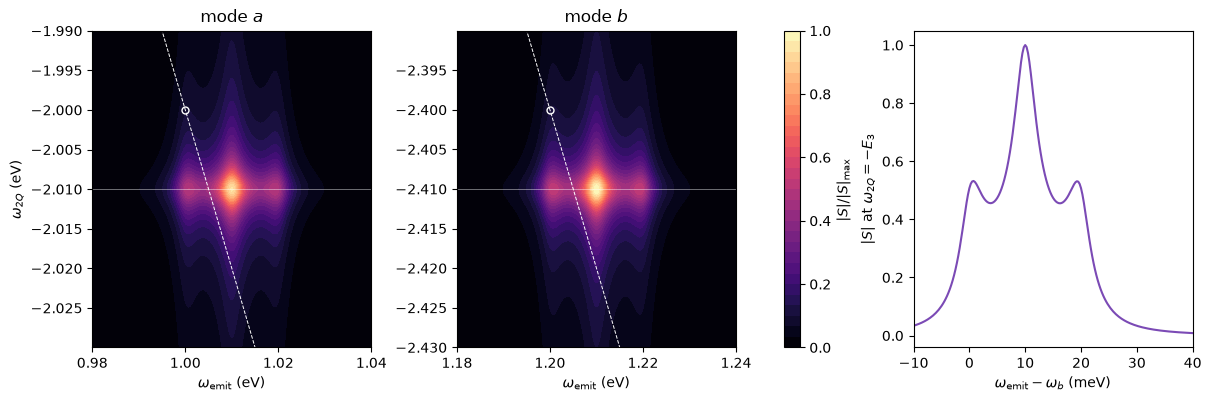

In [10]:
# The zoom windows are drawn on a grid four times finer than the map of the example (0.25 meV against 2 and 1 meV);
# the numbers of the text are read on the 251 x 301 grid of the map.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9), constrained_layout=True, gridspec_kw={"width_ratios": [1, 1, 1]})
windows = {}
for axis, mode_label, center_2q, center_emit in ((axes[0], "a", -E_two[0], 1.0 + EX2["anharmonicity"]),
                                                 (axes[1], "b", -E_two[2], 1.2 + EX2["anharmonicity"])):
    fine_axes = {"omega_2q": np.linspace(center_2q - 0.02, center_2q + 0.02, 161),
                 "omega_emit": np.linspace(center_emit - 0.03, center_emit + 0.03, 241)}
    block = np.abs(calculate_case(axes=fine_axes)["spectrum"]) / top
    windows[mode_label] = (fine_axes, block)
    image = axis.contourf(fine_axes["omega_emit"], fine_axes["omega_2q"], block, levels=np.linspace(0, 1, 31), cmap="magma")
    axis.axhline(center_2q, color="white", lw=0.6, alpha=0.5)
    axis.plot(fine_axes["omega_emit"], -2 * fine_axes["omega_emit"], color="white", ls="--", lw=0.7)   # omega_2Q = -2 omega_emit
    omega_m = center_emit - EX2["anharmonicity"]
    axis.plot(omega_m, -2 * omega_m, "o", mfc="none", mec="white", ms=5)       # the three lines of a harmonic mode (Delta = 0)
    axis.set_xlim(fine_axes["omega_emit"][[0, -1]])
    axis.set_ylim(fine_axes["omega_2q"][[0, -1]])
    axis.set_xlabel(r"$\omega_{\mathrm{emit}}$ (eV)")
    axis.set_title(f"mode ${mode_label}$")
    print(f"mode {mode_label}: maximum of the window on the fine grid {block.max():.4f} of the maximum of the map")
axes[0].set_ylabel(r"$\omega_{2Q}$ (eV)")
fine_axes, block = windows["b"]
cut = block[int(np.argmin(np.abs(fine_axes["omega_2q"] + E_two[2])))]
axes[2].plot(1e3 * (fine_axes["omega_emit"] - 1.2), cut / cut.max(), color="#7b4ab5")
axes[2].set_xlim(-10, 40)
axes[2].set_xlabel(r"$\omega_{\mathrm{emit}}-\omega_b$ (meV)")
axes[2].set_ylabel(r"$|S|$ at $\omega_{2Q}=-E_3$")
fig.colorbar(image, ax=axes[:2], label=r"$|S|/|S|_{\max}$", ticks=np.linspace(0, 1, 6))
fig.savefig(ANALYSIS_FIGURES / "example2_chi5_zoom.pdf", bbox_inches="tight")
plt.show()

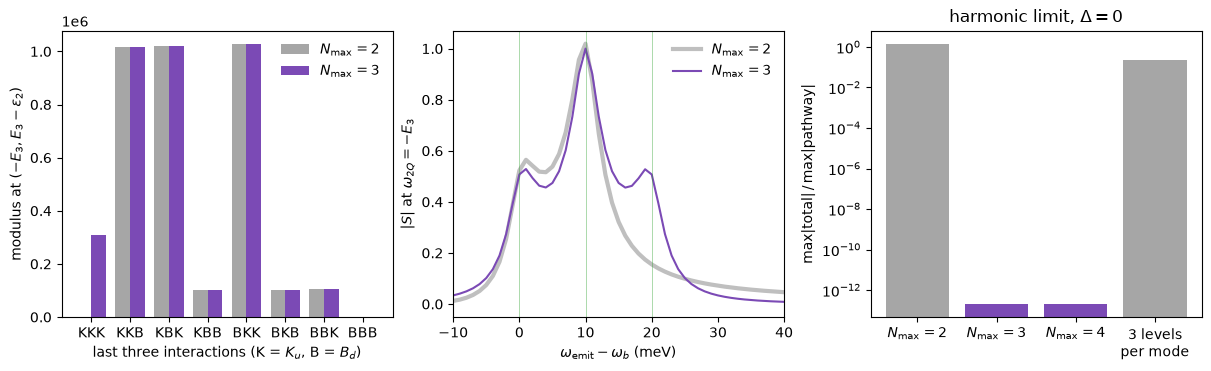

saved C:\Users\falve\OneDrive\Documents\GitHub\QuDPy-FDGF\validation\results\data\example2_chi5_analysis.json


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
x, width = np.arange(len(orderings)), 0.38
axes[0].bar(x - width / 2, [amp_n2[k] for k in orderings], width, label=r"$N_{\max}=2$", color="0.65")
axes[0].bar(x + width / 2, [amp_n3[k] for k in orderings], width, label=r"$N_{\max}=3$", color="#7b4ab5")
axes[0].set_xticks(x, orderings)
axes[0].set_ylabel(r"modulus at $(-E_3,E_3-\varepsilon_2)$")
axes[0].set_xlabel("last three interactions (K = $K_u$, B = $B_d$)")
axes[0].legend(frameon=False)

axes[1].plot(1e3 * (omega_emit - 1.2), cut_n2 / cut_n3.max(), lw=3.0, color="0.75", label=r"$N_{\max}=2$")
axes[1].plot(1e3 * (omega_emit - 1.2), cut_n3 / cut_n3.max(), lw=1.5, color="#7b4ab5", label=r"$N_{\max}=3$")
for transition in third_family:
    axes[1].axvline(1e3 * (transition - 1.2), color="#2ca02c", lw=0.7, alpha=0.4)
axes[1].set_xlim(-10, 40)
axes[1].set_xlabel(r"$\omega_{\mathrm{emit}}-\omega_b$ (meV)")
axes[1].set_ylabel(r"$|S|$ at $\omega_{2Q}=-E_3$")
axes[1].legend(frameon=False)

labels = list(harmonic)
values = [harmonic[k][1] for k in labels]
axes[2].bar(range(len(labels)), values, color=["0.65", "#7b4ab5", "#7b4ab5", "0.65"])
axes[2].set_yscale("log")
axes[2].set_xticks(range(len(labels)), [l.replace("three levels per mode", "3 levels\nper mode").replace("N_max=", r"$N_{\max}=$") for l in labels])
axes[2].set_ylabel(r"$\max|\mathrm{total}|\,/\,\max|\mathrm{pathway}|$")
axes[2].set_title(r"harmonic limit, $\Delta=0$")
fig.savefig(ANALYSIS_FIGURES / "example2_chi5_validation.pdf", bbox_inches="tight")
plt.show()

with open(DATA / "example2_chi5_analysis.json", "w") as handle:
    json.dump(numbers, handle, indent=1, default=lambda o: o if isinstance(o, (int, float, str)) else str(o))
print("saved", DATA / "example2_chi5_analysis.json")

## Summary

- The third-order response of the closed model is the same on three truncations: the states with $n_a+n_b\le2$, those with $n_a+n_b\le3$ and three levels per mode.
- The map has six lines, three for each mode, at $\omega_{2Q}=-(2\omega_m+\Delta)$ and $\omega_{\rm emit}=\omega_m$, $\omega_m+\Delta$, $\omega_m+2\Delta$; the mixed state $|1,1\rangle$ appears only through the coupling.
- Seven pathways are generated; six of the eight orderings of the last three interactions are identical with and without the three-excitation manifold, the all-$K_u$ ordering needs it, and the all-$B_d$ ordering never occurs.
- Truncating at two excitations changes the maximum by a few per cent but the complex spectrum by almost its whole maximum, because the missing pathway is large.
- The seven pathways cancel to $10^{-13}$ in the harmonic limit at $N_{\max}=3$ and $4$, and not at $N_{\max}=2$ or with three levels per mode.
- Two independent modes add to the machine precision with one-mode models that share no construction code with the coupled model.